In [1]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')

if not os.path.isdir('/content/siren'):
    !git clone -q https://github.com/vsitzmann/siren /content/siren
%cd /content/siren
!pip install -q cmapy scikit-video configargparse kagglehub

# scikit-video patch (same as before)
import skvideo
d = os.path.dirname(skvideo.__file__)
!grep -rl "np\.float\b\|np\.int\b\|np\.bool\b" {d} | xargs -r sed -i -E 's/np\.float\b/np.float64/g; s/np\.int\b/np.int_/g; s/np\.bool\b/np.bool_/g'

# utils.py refers to a class that does not exist (same fix as Fig. 5)
!sed -i 's/isinstance(model, meta_modules.NeuralProcessImplicit2DHypernetBVP)/False/' utils.py

# Download CelebA (Kaggle: jessicali9530/celeba-dataset, about 1.4 GB) to the local disk
import kagglehub
CELEBA = kagglehub.dataset_download("jessicali9530/celeba-dataset")
print("CelebA:", CELEBA)
assert os.path.exists(f"{CELEBA}/list_eval_partition.csv")
n = len(glob.glob(f"{CELEBA}/img_align_celeba/img_align_celeba/*.jpg"))
print("images:", n)          # should be 202599
assert n == 202599

# Replace the hard-coded official path with the download location
!sed -i "s#/media/data3/awb/CelebA/kaggle#{CELEBA}#g" dataio.py
!grep -n "img_align_celeba\|list_eval_partition" dataio.py

!python -c "import dataio; d = dataio.CelebA('train', downsampled=True); print('train:', len(d), d[0].size)"


Mounted at /content/drive
/content/siren
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|██████████| 1.33G/1.33G [00:10<00:00, 132MB/s]

Extracting files...


CelebA: /root/.cache/kagglehub/datasets/jessicali9530/celeba-dataset/versions/2
images: 202599
503:        self.root = '/root/.cache/kagglehub/datasets/jessicali9530/celeba-dataset/versions/2/img_align_celeba/img_align_celeba'
507:        with open('/root/.cache/kagglehub/datasets/jessicali9530/celeba-dataset/versions/2/list_eval_partition.csv', newline='') as csvfile:
train: 162770 (32, 32)


In [3]:
%cd /content/siren
!sed -i 's/^import skimage.measure$/import skimage.measure\nimport skimage.metrics/' utils.py
!sed -i 's/skimage.measure.compare_ssim(p, trgt, multichannel=True, data_range=1)/skimage.metrics.structural_similarity(p, trgt, channel_axis=-1, data_range=1)/' utils.py
!sed -i 's/skimage.measure.compare_psnr(/skimage.metrics.peak_signal_noise_ratio(/' utils.py
!grep -n "skimage.metrics" utils.py

# The failed run already created this folder; delete it first, otherwise the script stops and asks to overwrite
LOG = "/content/drive/MyDrive/siren_reproduction/logs"
!rm -rf {LOG}/celeba_cnp
!python experiment_scripts/train_img_neural_process.py --experiment_name celeba_cnp --conv_encoder --epochs_til_ckpt 50 --logging_root {LOG}

/content/siren
9:import skimage.metrics
587:        ssim = skimage.metrics.structural_similarity(p, trgt, channel_axis=-1, data_range=1)
588:        psnr = skimage.metrics.peak_signal_noise_ratio(p, trgt, data_range=1)
I0000 00:00:1794973802.171571    3698 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794973802.203257    3698 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794973803.436161    3698 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off

In [1]:
import os, glob
from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

LOG = "/content/drive/MyDrive/siren_reproduction/logs"
CKPT = f"{LOG}/celeba_cnp/checkpoints/model_final.pth"
assert os.path.exists(CKPT), "model_final.pth not found; training may not have finished"

# ---------- If the runtime was reset, set up the environment again (same as for training) ----------
if not os.path.isdir('/content/siren'):
    !git clone -q https://github.com/vsitzmann/siren /content/siren
%cd /content/siren
!pip install -q cmapy scikit-video configargparse kagglehub
import skvideo
d = os.path.dirname(skvideo.__file__)
!grep -rl "np\.float\b\|np\.int\b\|np\.bool\b" {d} | xargs -r sed -i -E 's/np\.float\b/np.float64/g; s/np\.int\b/np.int_/g; s/np\.bool\b/np.bool_/g'
!sed -i 's/isinstance(model, meta_modules.NeuralProcessImplicit2DHypernetBVP)/False/' utils.py
!grep -q "import skimage.metrics" utils.py || sed -i 's/^import skimage.measure$/import skimage.measure\nimport skimage.metrics/' utils.py
!sed -i 's/skimage.measure.compare_ssim(p, trgt, multichannel=True, data_range=1)/skimage.metrics.structural_similarity(p, trgt, channel_axis=-1, data_range=1)/' utils.py
!sed -i 's/skimage.measure.compare_psnr(/skimage.metrics.peak_signal_noise_ratio(/' utils.py

import kagglehub
CELEBA = kagglehub.dataset_download("jessicali9530/celeba-dataset")
!sed -i "s#/media/data3/awb/CelebA/kaggle#{CELEBA}#g" dataio.py

# ---------- Test script patch: the first three extra experiments save float images; convert them to uint8 before saving ----------
p = "experiment_scripts/test_conv_neural_process.py"
s = open(p).read()
if "_imwrite_u8" not in s:
    s = s.replace("import imageio\n", "import imageio\n"
        "_imwrite = imageio.imwrite\n"
        "def _imwrite_u8(path, img, *a, **k):\n"
        "    if getattr(img, 'dtype', None) is not None and img.dtype != np.uint8:\n"
        "        img = (np.clip(img, 0, 1) * 255).round().astype(np.uint8)\n"
        "    return _imwrite(path, img, *a, **k)\n"
        "imageio.imwrite = _imwrite_u8\n", 1)
    open(p, "w").write(s)

# ---------- Official test ----------
# Output folder = logging_root / <name of the folder 3 levels above the checkpoint>_<experiment_name> = /content/celeba_test/celeba_cnp_test
!python experiment_scripts/test_conv_neural_process.py --checkpoint_path {CKPT} --experiment_name test --logging_root /content/celeba_test

# ---------- Save the results to Drive (MSE + the first 200 images of each setting) ----------
import shutil, numpy as np
SRC, DST = "/content/celeba_test/celeba_cnp_test", f"{LOG}/celeba_cnp_test"
os.makedirs(DST, exist_ok=True)
for f in glob.glob(f"{SRC}/*.npy") + glob.glob(f"{SRC}/*.png"):
    shutil.copy2(f, DST)
for sub in sorted(os.listdir(SRC)):
    if os.path.isdir(f"{SRC}/{sub}"):
        os.makedirs(f"{DST}/{sub}", exist_ok=True)
        for i in range(200):
            for name in [f"{i}.png", f"{i}_sparse.png"]:
                if os.path.exists(f"{SRC}/{sub}/{name}"):
                    shutil.copy2(f"{SRC}/{sub}/{name}", f"{DST}/{sub}/{name}")
for c in ["10", "100", "1000", "half", "full"]:
    print(f"context {c:>5}: mean MSE = {np.load(f'{SRC}/MSE_{c}_context.npy').mean():.5f}")
print("saved to", DST)

Mounted at /content/drive
/content/siren
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Using Colab cache for faster access to the 'celeba-dataset' dataset.
I0000 00:00:1795053098.655797    2241 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795053098.687032    2241 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795053099.915752    2241 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due t

/content/siren
test images: [3, 21, 12715, 10204, 16978]
SingleBVPNet(
  (image_downsampling): ImageDownsampling()
  (net): FCBlock(
    (net): MetaSequential(
      (0): MetaSequential(
        (0): BatchLinear(in_features=2, out_features=256, bias=True)
        (1): Sine()
      )
      (1): MetaSequential(
        (0): BatchLinear(in_features=256, out_features=256, bias=True)
        (1): Sine()
      )
      (2): MetaSequential(
        (0): BatchLinear(in_features=256, out_features=256, bias=True)
        (1): Sine()
      )
      (3): MetaSequential(
        (0): BatchLinear(in_features=256, out_features=256, bias=True)
        (1): Sine()
      )
      (4): MetaSequential(
        (0): BatchLinear(in_features=256, out_features=3, bias=True)
      )
    )
  )
)
ConvolutionalNeuralProcessImplicit2DHypernet(
  (encoder): ConvImgEncoder(
    (conv_theta): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu): ReLU(inplace=True)
    (cnn): Sequential(
      (0)

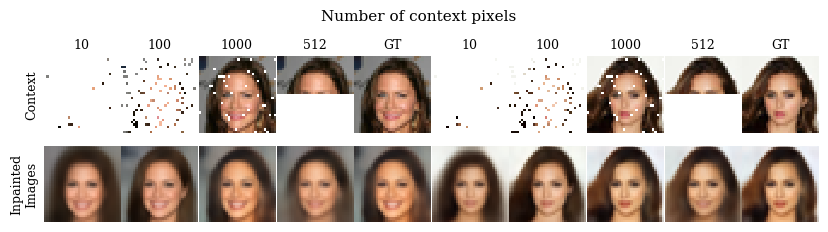

saved: /content/drive/MyDrive/siren_reproduction/fig6_reproduction.png


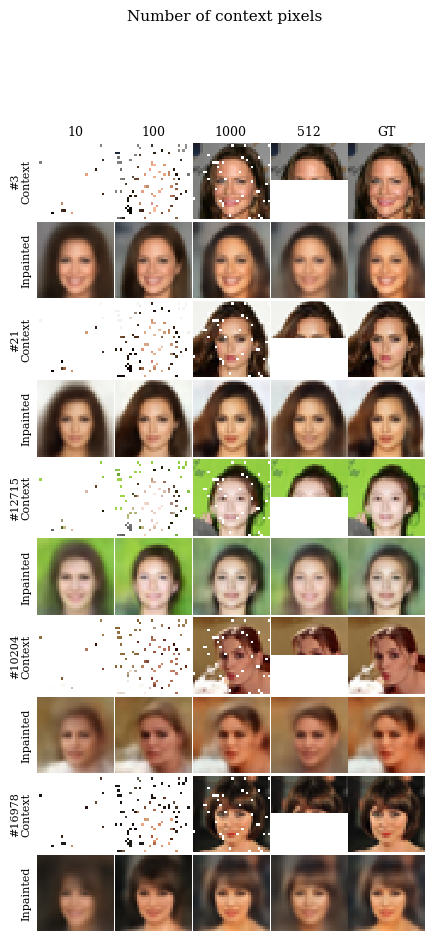

saved: /content/drive/MyDrive/siren_reproduction/fig6_more.png


In [5]:
%cd /content/siren
import numpy as np, torch, matplotlib.pyplot as plt
import dataio, meta_modules

LOG = "/content/drive/MyDrive/siren_reproduction/logs"
FIG = "/content/drive/MyDrive/siren_reproduction"
CKPT = f"{LOG}/celeba_cnp/checkpoints/model_final.pth"

# ---- Images: 3 and 21 are always used, plus 3 random test images (fixed seed, reproducible) ----
N_TEST = len(dataio.CelebA(split="test", downsampled=True))
rng = np.random.default_rng(0)
extra = [int(i) for i in rng.choice([i for i in range(N_TEST) if i not in (3, 21)], 3, replace=False)]
IDX = [3, 21] + extra
print("test images:", IDX)

# ---- Model ----
model = meta_modules.ConvolutionalNeuralProcessImplicit2DHypernet(in_features=3, out_features=3,
                                                                   image_resolution=(32, 32))
model.load_state_dict(torch.load(CKPT)); model.cuda().eval()
ds = dataio.ImageGeneralizationWrapper(
    dataio.Implicit2DWrapper(dataio.CelebA(split="test", downsampled=True), sidelength=(32, 32)),
    test_sparsity=10, generalization_mode="conv_cnp_test")

to_img = lambda t: np.clip((t + 1) / 2, 0, 1)                      # [-1, 1] -> [0, 1], as in the test script

def run(idx, sparsity, seed=0):
    torch.manual_seed(seed)                                         # fix the sampled context pixels
    ds.update_test_sparsity(sparsity)
    inp, gt = ds[idx]
    with torch.no_grad():
        out = model({"coords": inp["coords"][None].cuda(), "img_sparse": inp["img_sparse"][None].cuda()})
    pred = to_img(dataio.lin2img(out["model_out"], (32, 32))[0].permute(1, 2, 0).cpu().numpy())
    sp = inp["img_sparse"].permute(1, 2, 0).numpy()
    mask = (sp == 0).sum(2) == 3                                    # pixels not given to the model are shown white, as in the test script
    sp = to_img(sp); sp[mask] = 1.
    return sp, pred, to_img(gt["img"].view(32, 32, 3).numpy())

COLS = [("10", 10), ("100", 100), ("1000", 1000), ("512", "half"), ("GT", "full")]
def tiles(idx):                                                     # (top, bottom) for each column
    out = []
    for lab, s in COLS:
        sp, pred, gt = run(idx, s)
        out.append((gt if lab == "GT" else sp, pred))               # GT column: original image / reconstruction from the full image as context
    return out

def clean(a):
    a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values(): s.set_visible(False)

def save(name):
    for ext in ["png", "pdf"]:
        plt.savefig(f"{FIG}/{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show(); print("saved:", f"{FIG}/{name}.png")

T = {i: tiles(i) for i in IDX}

# ---- Figure 1: paper layout, 3 and 21 side by side ----
fig, ax = plt.subplots(2, 10, figsize=(10, 2.3), gridspec_kw=dict(wspace=0.02, hspace=0.02))
for f, i in enumerate([3, 21]):
    for c, (top, bot) in enumerate(T[i]):
        ax[0, f * 5 + c].imshow(top, interpolation="nearest"); ax[1, f * 5 + c].imshow(bot, interpolation="nearest")
        ax[0, f * 5 + c].set_title(COLS[c][0], fontsize=9, family="serif")
for a in ax.flat: clean(a)
ax[0, 0].set_ylabel("Context", fontsize=9, family="serif")
ax[1, 0].set_ylabel("Inpainted\nImages", fontsize=9, family="serif")
fig.suptitle("Number of context pixels", fontsize=11, family="serif", y=1.06)
save("fig6_reproduction")

# ---- Figure 2: 5 faces, two rows each ----
fig, ax = plt.subplots(2 * len(IDX), 5, figsize=(5, 2.05 * len(IDX)), gridspec_kw=dict(wspace=0.02, hspace=0.02))
for f, i in enumerate(IDX):
    for c, (top, bot) in enumerate(T[i]):
        ax[2 * f, c].imshow(top, interpolation="nearest"); ax[2 * f + 1, c].imshow(bot, interpolation="nearest")
    ax[2 * f, 0].set_ylabel(f"#{i}\nContext", fontsize=8, family="serif")
    ax[2 * f + 1, 0].set_ylabel("Inpainted", fontsize=8, family="serif")
for c, (lab, _) in enumerate(COLS): ax[0, c].set_title(lab, fontsize=9, family="serif")
for a in ax.flat: clean(a)
fig.suptitle("Number of context pixels", fontsize=11, family="serif", y=1.01)
save("fig6_more")